<div style="text-align: center;"><h1 style="margin-bottom: 10px; font-weight: bold;">PREDICTIVE MODELING</h1></div>

## **Objective**

Build and evaluate classification models to predict employee attrition and identify factors associated with employee turnover risk.

## **Import Dataset**

In [1]:
import pandas as pd
df = pd.read_csv("../data/processed/hr_employee_master.csv")

## **Target Variable**

The target variable is `Attrition`, which indicates whether an employee left the organization (`Yes`) or stayed (`No`).

## **Feature Preparation**

Prepare the features for model training by removing non-predictive and EDA-only columns.


In [2]:
drop_cols = ["EmployeeID", "Tenure_Group", "Promotion_Group", "Manager_Tenure_Group"]

drop_cols = [col for col in drop_cols if col in df.columns]

X = df.drop(columns=["Attrition"] + drop_cols)
y = df["Attrition"]

print("Features:", X.shape[1])
print("Target:", y.name)

Features: 24
Target: Attrition


## **Train-Test Split**

In [3]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    stratify=y,
    random_state=42
)

print("Training set:", X_train.shape)
print("Test set:", X_test.shape)

Training set: (3528, 24)
Test set: (882, 24)


In [4]:
X.dtypes

Age                          int64
BusinessTravel                 str
Department                     str
DistanceFromHome             int64
Education                    int64
EducationField                 str
Gender                         str
JobLevel                     int64
JobRole                        str
MaritalStatus                  str
MonthlyIncome                int64
NumCompaniesWorked         float64
PercentSalaryHike            int64
StockOptionLevel             int64
TotalWorkingYears          float64
TrainingTimesLastYear        int64
YearsAtCompany               int64
YearsSinceLastPromotion      int64
YearsWithCurrManager         int64
EnvironmentSatisfaction    float64
JobSatisfaction            float64
WorkLifeBalance            float64
JobInvolvement               int64
PerformanceRating            int64
dtype: object

## **Preprocessing**

Categorical features will be one-hot encoded, while numerical and ordinal features will be retained in numeric form. Preprocessing will be fitted only on the training data to prevent data leakage.

In [5]:
categorical = [
    "BusinessTravel", "Department", "EducationField",
    "Gender", "JobRole", "MaritalStatus"
]

numeric = [
    "Age", "DistanceFromHome", "Education", "JobLevel",
    "MonthlyIncome", "NumCompaniesWorked", "PercentSalaryHike",
    "StockOptionLevel", "TotalWorkingYears", "TrainingTimesLastYear",
    "YearsAtCompany", "YearsSinceLastPromotion", "YearsWithCurrManager",
    "EnvironmentSatisfaction", "JobSatisfaction", "WorkLifeBalance",
    "JobInvolvement", "PerformanceRating"
]

print("Categorical:", len(categorical))
print("Numeric/Ordinal:", len(numeric))

Categorical: 6
Numeric/Ordinal: 18


### Preprocessing Pipeline

Categorical features will be one-hot encoded, while numerical and ordinal features will be standardized for model training.

In [6]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

preprocessor = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore"), categorical),
    ("num", StandardScaler(), numeric)
])

## **Logistic Regression**

Logistic Regression is used as the baseline classification model for predicting employee attrition.

### Model Training

In [7]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

logreg = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ))
])

logreg.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](2,)","['No','Yes']"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](24,)","['Age','BusinessTravel','Department',...,'WorkLifeBalance', 'JobInvolvement','PerformanceRating']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,24
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('cat', ...), ('num', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying

### Prediction

In [8]:
y_pred_logreg = logreg.predict(X_test)
y_prob_logreg = logreg.predict_proba(X_test)[:, 1]

print("Predictions generated successfully.")

Predictions generated successfully.


## **Random Forest**

Random Forest is used as a tree-based classification model to capture non-linear relationships and interactions among features.

### Model Training

In [9]:
from sklearn.ensemble import RandomForestClassifier

rf = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        class_weight="balanced"
    ))
])

rf.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](2,)","['No','Yes']"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](24,)","['Age','BusinessTravel','Department',...,'WorkLifeBalance', 'JobInvolvement','PerformanceRating']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,24
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('cat', ...), ('num', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying

### Prediction

In [10]:
y_pred_rf = rf.predict(X_test)
y_prob_rf = rf.predict_proba(X_test)[:, 1]

print("Predictions generated successfully.")

Predictions generated successfully.


## **Model Evaluation**

The models are evaluated using Accuracy, Precision, Recall, F1-score, and ROC-AUC for the attrition class.

### Classification Metrics

In [11]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

models = {
    "Logistic Regression": (y_pred_logreg, y_prob_logreg),
    "Random Forest": (y_pred_rf, y_prob_rf)
}

for name, (y_pred, y_prob) in models.items():
    print(f"\n{name}")
    print("Accuracy :", round(accuracy_score(y_test, y_pred), 4))
    print("Precision:", round(precision_score(y_test, y_pred, pos_label="Yes"), 4))
    print("Recall   :", round(recall_score(y_test, y_pred, pos_label="Yes"), 4))
    print("F1-Score :", round(f1_score(y_test, y_pred, pos_label="Yes"), 4))
    print("ROC-AUC  :", round(roc_auc_score(y_test, y_prob), 4))


Logistic Regression
Accuracy : 0.7268
Precision: 0.3213
Recall   : 0.6268
F1-Score : 0.4248
ROC-AUC  : 0.7829

Random Forest
Accuracy : 0.9966
Precision: 1.0
Recall   : 0.9789
F1-Score : 0.9893
ROC-AUC  : 0.9987


### Confusion Matrix

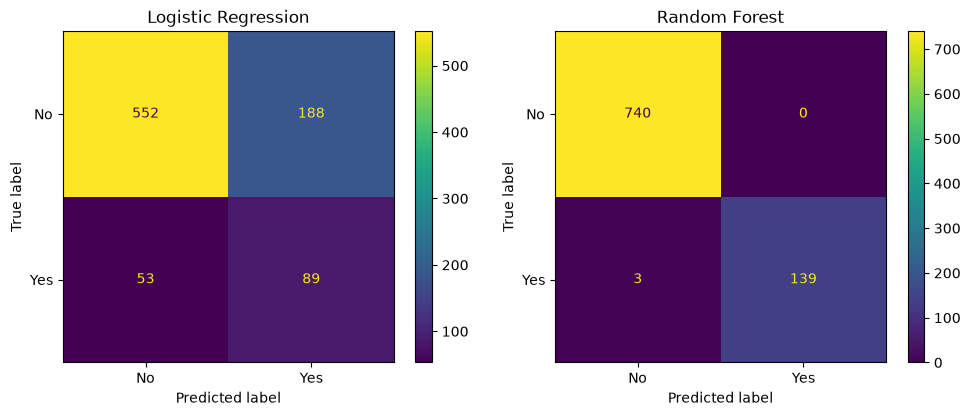

In [12]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

for ax, name, y_pred in zip(
    axes,
    ["Logistic Regression", "Random Forest"],
    [y_pred_logreg, y_pred_rf]
):
    cm = confusion_matrix(y_test, y_pred, labels=["No", "Yes"])
    ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["No", "Yes"]
    ).plot(ax=ax)

    ax.set_title(name)

plt.tight_layout()
plt.show()

### Random Forest Feature Importance

The most influential features are inspected to check whether any feature may be contributing to unusually high model performance.

In [13]:
feature_names = rf.named_steps["preprocessor"].get_feature_names_out()
importances = rf.named_steps["model"].feature_importances_

importance_df = (
    pd.DataFrame({
        "Feature": feature_names,
        "Importance": importances
    })
    .sort_values("Importance", ascending=False)
    .head(15)
)

importance_df

,Feature,Importance
26,num__Age,0.081628
34,num__TotalWorkingYears,0.070911
30,num__MonthlyIncome,0.068438
36,num__YearsAtCompany,0.066488
27,num__DistanceFromHome,0.056128
38,num__YearsWithCurrManager,0.055616
32,num__PercentSalaryHike,0.044859
31,num__NumCompaniesWorked,0.043563
39,num__EnvironmentSatisfaction,0.039450
40,num__JobSatisfaction,0.036749


## **Model Comparison**

The performance of Logistic Regression and Random Forest is compared across the selected classification metrics.

In [14]:
from sklearn.metrics import classification_report, roc_auc_score

comparison_df = pd.DataFrame([
    classification_report(y_test, y_pred_logreg, output_dict=True)["Yes"],
    classification_report(y_test, y_pred_rf, output_dict=True)["Yes"]
], index=["Logistic Regression", "Random Forest"])[["precision", "recall", "f1-score"]]

comparison_df["ROC-AUC"] = [
    roc_auc_score(y_test, y_prob_logreg),
    roc_auc_score(y_test, y_prob_rf)
]

comparison_df.round(4)

,precision,recall,f1-score,ROC-AUC
Logistic Regression,0.3213,0.6268,0.4248,0.7829
Random Forest,1.0000,0.9789,0.9893,0.9987


In [17]:
## Save trained Random Forest pipeline
import os
os.makedirs("../models", exist_ok=True)
import joblib
joblib.dump(rf, "../models/random_forest_pipeline.pkl")

['../models/random_forest_pipeline.pkl']

## **Conclusion**

Random Forest achieved higher performance than Logistic Regression in predicting employee attrition on the test set.